# Neural Networks · First laboratory
### Python, arrays, and the meaning of a weight

2 October 2026 · Cristian Simionescu · English student edition

## Goal
Represent a small image as numbers, predict array shapes, compute a batch of weighted scores, and explain why performance on unseen examples matters.

**Core route:** sections 1–7, then the exercises and exit ticket. The matrix animation is a short optional demonstration. Training is in a separate optional notebook.

This supplements the published 2026 Lab 1 and Course 1. All example data below are synthetic teaching data. The detector weights are hand-designed, not learned.

## Setup
Run cells in order with Shift+Enter. The only numerical dependencies are NumPy and Matplotlib. See `../SETUP.md` for installation. No network, GPU, or dataset download is needed after setup.

In [16]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "animation.embed_limit": 25})
BLUE, ORANGE = "#2458a6", "#be5514"
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.11.13 | NumPy 1.24.2 | Matplotlib 3.8.0


## Steps
### 1. Python warm-up: predict before running
What will `values * 2` do? What changes when `values` is an array?

A list is a general container. A numerical array has a shape and a shared dtype. Type annotations document intent; they do not automatically enforce types at runtime.

In [17]:
values = [1, 2, 3]
array = np.array(values, dtype=float)
print("List * 2:", values * 2)
print("Array * 2:", array * 2)
print("Positive entries:", np.array([-2, 0, 3, 5])[np.array([-2, 0, 3, 5]) > 0])

def weighted_sum(values, weights):
    if len(values) != len(weights):
        raise ValueError("One weight is required for each input")
    return sum(value * weight for value, weight in zip(values, weights))

print("Python weighted sum:", weighted_sum([2, 3], [0.5, -1]))
assert weighted_sum([2, 3], [0.5, -1]) == -2

List * 2: [1, 2, 3, 1, 2, 3]
Array * 2: [2. 4. 6.]
Positive entries: [3 5]
Python weighted sum: -2.0


### 2. A picture is an array
These are two 5×5 grayscale pictures. A value of 1 means bright and 0 means dark. Flattening preserves the values and changes how we address them.

**Predict:** How many inputs does one fully connected neuron need for one picture? What shape represents four pictures?

Images: (4, 5, 5) Batch of feature vectors: (4, 25)


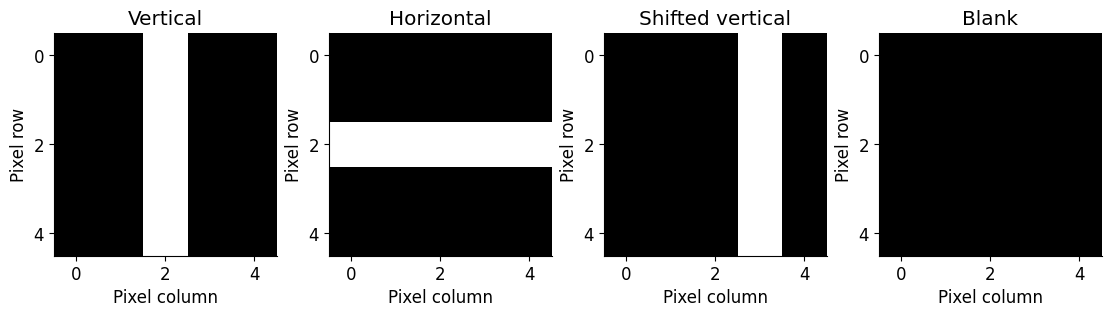

In [18]:
vertical = np.zeros((5, 5), dtype=float)
vertical[:, 2] = 1
horizontal = np.zeros((5, 5), dtype=float)
horizontal[2, :] = 1
shifted_vertical = np.roll(vertical, 1, axis=1)
blank = np.zeros((5, 5), dtype=float)
images = np.stack([vertical, horizontal, shifted_vertical, blank])
names = ["Vertical", "Horizontal", "Shifted vertical", "Blank"]
X = images.reshape(len(images), -1)
print("Images:", images.shape, "Batch of feature vectors:", X.shape)
assert X.shape == (4, 25)
assert np.array_equal(X[0].reshape(5, 5), vertical)

fig, axes = plt.subplots(1, 4, figsize=(11, 3), layout="constrained")
for ax, name, picture in zip(axes, names, images):
    ax.imshow(picture, cmap="gray", vmin=0, vmax=1)
    ax.set(title=name, xlabel="Pixel column", ylabel="Pixel row", xticks=[0, 2, 4], yticks=[0, 2, 4])
plt.show()

**Try:** change the central column to a diagonal using `np.eye(5)`. Is its shape different? Is its information different?

### 3. A weight says what to reward and what to penalize
The vertical detector rewards the centre column and penalizes the other pixels. A dot product multiplies each input by its weight, then adds the contributions.

For a single image, `score = x @ w + b`. These scores are arbitrary real values, not probabilities.

{'Vertical': 3.0, 'Horizontal': -2.0, 'Shifted vertical': -3.25, 'Blank': -2.0}


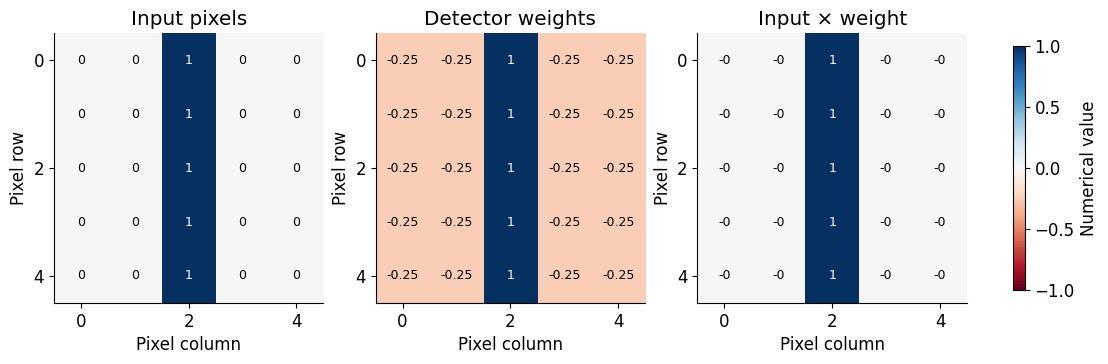

In [19]:
weights = np.full((5, 5), -0.25)
weights[:, 2] = 1.0
w = weights.reshape(-1)
b = -2.0
scores = X @ w + b
print(dict(zip(names, scores)))
assert np.allclose(scores, [3, -2, -3.25, -2])
assert np.isclose(weighted_sum(X[0], w) + b, scores[0])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, data, title in zip(axes, [vertical, weights, vertical * weights],
                         ["Input pixels", "Detector weights", "Input × weight"]):
    im = ax.imshow(data, cmap="RdBu", vmin=-1, vmax=1)
    ax.set(title=title, xlabel="Pixel column", ylabel="Pixel row", xticks=[0, 2, 4], yticks=[0, 2, 4])
    for row in range(5):
        for col in range(5):
            ax.text(col, row, f"{data[row, col]:g}", ha="center", va="center",
                    fontsize=9, color="white" if abs(data[row,col]) > .6 else "black")
fig.colorbar(im, ax=axes, shrink=.8, label="Numerical value")
plt.show()

**Pause:** A shifted vertical line receives a negative score. This detector recognizes a location-specific pattern. Seeing two successful examples would not establish that it understands every vertical line.

The bias moves the threshold: with this choice, a raw weighted sum must reach 2 to produce a nonnegative score. Training will later choose weights and biases from examples.

### 4. One matrix multiplication, several detectors
Rows of `X` are examples. Columns of `W` are detectors. We use `X @ W + biases` here.

`(4, 25) @ (25, 2) + (2,)` produces `(4, 2)`.

This is the NumPy convention in this notebook. PyTorch `nn.Linear` stores its weight matrix as `(outputs, inputs)` and uses its transpose for a row-batch input.

In [20]:
W = np.column_stack([weights.reshape(-1), weights.T.reshape(-1)])
biases = np.array([-2., -2.])
batch_scores = X @ W + biases
assert batch_scores.shape == (4, 2)
assert np.allclose(batch_scores[:, 0], scores)
print("             vertical  horizontal")
for name, row in zip(names, batch_scores):
    print(f"{name:16s} {row}")
print("First row equals individual prediction:", np.allclose(X[0] @ W + biases, batch_scores[0]))

             vertical  horizontal
Vertical         [ 3. -2.]
Horizontal       [-2.  3.]
Shifted vertical [-3.25 -2.  ]
Blank            [-2. -2.]
First row equals individual prediction: True


The blank image scores equally for both classes. `argmax` would still choose an index. A forced choice is not evidence of confidence.

### 5. Shape reasoning: reductions and broadcasting
For a matrix `(examples, features)`, `mean(axis=0)` reduces the examples axis, leaving one mean per feature. `mean(axis=1)` leaves one mean per example.

Broadcasting compares shapes from the right: corresponding sizes must be equal or one must be 1. Missing leading dimensions act like 1. See [NumPy broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html).

In [21]:
A = np.arange(1, 7, dtype=float).reshape(2, 3)
print("A =", A, sep="\n")
print("Feature means, axis 0:", A.mean(axis=0))
print("Example means, axis 1:", A.mean(axis=1))
print("Per-feature offsets:", A + np.array([10, 20, 30]), sep="\n")
print("Per-example offsets:", A + np.array([10, 20])[:, None], sep="\n")
print("One column:", A[:, 0].shape, "Preserved column axis:", A[:, 0:1].shape)
assert A[:, 0].shape == (2,)
assert A[:, 0:1].shape == (2, 1)

A =
[[1. 2. 3.]
 [4. 5. 6.]]
Feature means, axis 0: [2.5 3.5 4.5]
Example means, axis 1: [2. 5.]
Per-feature offsets:
[[11. 22. 33.]
 [14. 25. 36.]]
Per-example offsets:
[[11. 12. 13.]
 [24. 25. 26.]]
One column: (2,) Preserved column axis: (2, 1)


**A bug that runs without an exception:** a target of shape `(n, 1)` subtracted from a prediction of shape `(n,)` produces `(n, n)`. Each target is compared with every prediction.

Wrong: (3, 3) Correct: (3,)


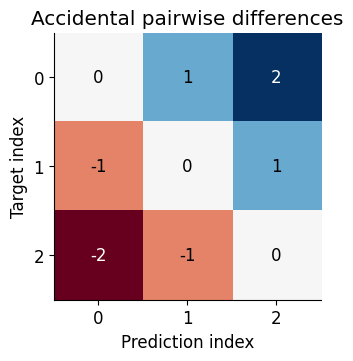

In [22]:
prediction = np.array([1., 2., 3.])
target_column = np.array([[1.], [2.], [3.]])
wrong_error = prediction - target_column
right_error = prediction - target_column.reshape(-1)
print("Wrong:", wrong_error.shape, "Correct:", right_error.shape)
assert wrong_error.shape == (3, 3)
assert right_error.shape == (3,)
assert np.allclose(right_error, 0)

fig, ax = plt.subplots(figsize=(4.6, 3.5), layout="constrained")
ax.imshow(wrong_error, cmap="RdBu", vmin=-2, vmax=2)
for row in range(3):
    for col in range(3):
        ax.text(col, row, f"{wrong_error[row,col]:g}", ha="center", va="center", color="white" if abs(wrong_error[row,col])==2 else "black")
ax.set(title="Accidental pairwise differences", xlabel="Prediction index", ylabel="Target index", xticks=range(3), yticks=range(3))
plt.show()

### 6. Standardization, without leaking future information
Subtract each feature's training mean and divide by its training standard deviation. Use those same statistics for validation and test examples.

Our synthetic table has two varying features and one constant feature. We define the constant feature's scale as 1 to avoid division by zero. Population standard deviation (`ddof=0`) is used here.

In [23]:
train = np.array([[1., 100., 7.], [2., 200., 7.], [3., 300., 7.], [4., 400., 7.]])
validation = np.array([[5., 500., 7.]])
mean = train.mean(axis=0, keepdims=True)
std = train.std(axis=0, keepdims=True)
scale = np.where(std == 0, 1., std)
train_z = (train - mean) / scale
validation_z = (validation - mean) / scale
print("Training means:", mean)
print("Standardized training data:", train_z, sep="\n")
print("Validation using TRAINING statistics:", validation_z)
assert np.isfinite(train_z).all()
assert np.allclose(train_z.mean(axis=0), 0)
assert np.allclose(train_z[:, :2].std(axis=0), 1)
assert np.allclose(train_z[:, 2], 0)

Training means: [[  2.5 250.    7. ]]
Standardized training data:
[[-1.342 -1.342  0.   ]
 [-0.447 -0.447  0.   ]
 [ 0.447  0.447  0.   ]
 [ 1.342  1.342  0.   ]]
Validation using TRAINING statistics: [[2.236 2.236 0.   ]]


The validation row need not have zero mean. Fitting a new normalizer to each test batch changes the model's input meaning.

**Memory matters too:** a basic slice can share memory with its original array. In-place changes can modify both.

In [24]:
original = np.array([1., 2., 3.])
view = original[:2]
view -= 1
print("After editing a view:", original)
independent = original.copy()
independent[:] = 99
assert not np.shares_memory(original, independent)
assert np.array_equal(original, [0, 1, 3])
print("A copy can be changed independently:", independent)

After editing a view: [0. 1. 3.]
A copy can be changed independently: [99. 99. 99.]


### 7. Matrices move space
A 2×2 matrix tells us where the two basis vectors go. With column vectors we write `T @ point`; with a batch of row vectors we write `points @ T.T`.

Choose `T` below. Try a shear `[[1, 1], [0, 1]]`, a 90° rotation `[[0, -1], [1, 0]]`, or a collapse `[[1, 1], [0, 0]]`.

**Predict:** What happens to the unit square? Can every transformation be undone?

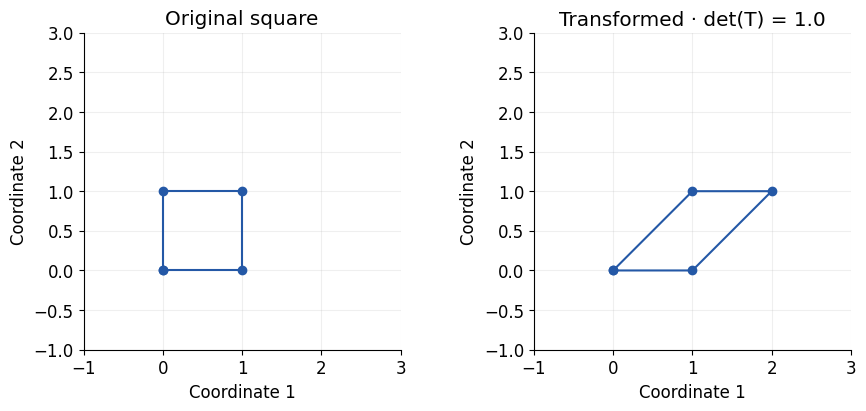

In [25]:
T = np.array([[1., 1.], [0., 1.]])
square = np.array([[0., 0.], [1., 0.], [1., 1.], [0., 1.], [0., 0.]])
transformed = square @ T.T
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, points, title in zip(axes, [square, transformed], ["Original square", f"Transformed · det(T) = {np.linalg.det(T):.1f}"]):
    ax.plot(points[:, 0], points[:, 1], "o-", color=BLUE)
    ax.set(xlim=(-1, 3), ylim=(-1, 3), xlabel="Coordinate 1", ylabel="Coordinate 2", title=title, aspect="equal")
    ax.grid(alpha=.2)
plt.show()
assert np.allclose(transformed[2], T @ square[2])

#### Optional animation: watch the grid shear
Play or drag the frame slider. This interpolation illustrates a transformation, not a learning algorithm. The final frame is the exact matrix `T` above. The static figure remains available if your viewer suppresses JavaScript.

In [26]:
grid_lines = []
for value in np.linspace(-1, 1, 5):
    grid_lines.extend([np.array([[-1., value], [1., value]]), np.array([[value, -1.], [value, 1.]])])
fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
ax.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), aspect="equal", xlabel="Coordinate 1", ylabel="Coordinate 2")
artists = [ax.plot([], [], color=BLUE, alpha=.5)[0] for _ in grid_lines]
border, = ax.plot([], [], color=ORANGE, lw=3)
title = ax.set_title("")
def animate_transform(frame):
    t = frame / 30
    current = (1-t) * np.eye(2) + t * T
    for artist, points in zip(artists, grid_lines):
        result = points @ current.T
        artist.set_data(result[:, 0], result[:, 1])
    result = square @ current.T
    border.set_data(result[:, 0], result[:, 1])
    title.set_text(f"Matrix interpolation · {t:.0%} of the way to T")
    return artists + [border, title]
animation = FuncAnimation(fig, animate_transform, frames=31, interval=80, blit=False)
animation_html = animation.to_jshtml(default_mode="once")
plt.close(fig)
display(HTML(animation_html))

The shear preserves area here: its determinant is 1. A singular transformation collapses a direction and cannot have an inverse.

Matrix order matters. The rightmost matrix acts first in column-vector notation.

In [27]:
rotation = np.array([[0., -1.], [1., 0.]])
stretch = np.diag([2., 1.])
point = np.array([1., 0.])
print("Rotate then stretch:", stretch @ rotation @ point)
print("Stretch then rotate:", rotation @ stretch @ point)
assert not np.allclose(stretch @ rotation @ point, rotation @ stretch @ point)

Rotate then stretch: [0. 1.]
Stretch then rotate: [0. 2.]


## Checks
### Pair exercises · 15 minutes
Replace `None` in each cell. The notebook runs before you solve the exercises, but prints **Not attempted**. A clean Run All by itself does not mean you completed them.

**E1. One batch, three outputs.** Create three detectors that compute the first feature, second feature, and sum of the two. Complete `exercise_W`.

In [28]:
exercise_X = np.array([[1., 2.], [3., 4.]])
exercise_W = None  # TODO: a (2, 3) matrix
if exercise_W is None:
    print("E1: Not attempted")
else:
    assert np.asarray(exercise_W).shape == (2, 3)
    assert np.allclose(exercise_X @ exercise_W, [[1, 2, 3], [3, 4, 7]])
    print("E1: Passed")

E1: Not attempted


**E2. Normalize per example.** Standardize each row of `exercise_X` independently. Keep the row dimension when computing the statistics so broadcasting works. Explain why this differs from the per-feature normalization earlier.

In [29]:
exercise_z = None  # TODO: standardize each row
if exercise_z is None:
    print("E2: Not attempted")
else:
    assert np.asarray(exercise_z).shape == exercise_X.shape
    assert np.allclose(exercise_z, [[-1, 1], [-1, 1]])
    print("E2: Passed")

E2: Not attempted


**E3. Plain Python matrix–vector multiplication.** Implement `matrix_vector` with lists and loops/comprehensions. This prepares the programming technique for Homework 1, without solving its assigned system.

In [30]:
def matrix_vector(matrix, vector):
    # TODO: validate row lengths, then compute one weighted sum per row
    return None

exercise_result = matrix_vector([[1, 2], [3, 4]], [2, -1])
if exercise_result is None:
    print("E3: Not attempted")
else:
    assert exercise_result == [0, 2]
    assert matrix_vector([[0, 1], [1, 0]], [5, 6]) == [6, 5]
    print("E3: Passed")

E3: Not attempted


### Exit ticket
1. What are the shapes of `X`, `W`, and `X @ W` for 10 images of 5×5 pixels and 3 detectors?
2. Why does `*` not replace `@` for a batch of predictions?
3. How could a detector succeed on our centred image and fail on a new image?
4. Which data should determine the normalization statistics?
5. Is a larger raw score automatically a calibrated probability?

## Next Steps
Lab 2 covers NumPy exercises, classification metrics, and Homework 1 (linear systems). **Homework 1 requires Python lists and no NumPy/linear algebra framework.** Follow the published Lab 2 deadline: before Lab 3. Confirm submission/presentation arrangements with your instructor.

For an optional taste of learning, open `LearningPreview.ipynb`.

### Focused resources
- [Current NN course page](https://sites.google.com/view/rbenchea/neural-networks): Course 1 on ML concepts, linear algebra, NumPy.
- [2026 Lab 1](https://github.com/Tensor-Reloaded/Neural-Networks-2026/tree/main/Lab01) and [Lab 2](https://github.com/Tensor-Reloaded/Neural-Networks-2026/tree/main/Lab02).
- [Original Python warm-up](https://github.com/Tensor-Reloaded/Neural-Networks-Template-2025/blob/main/Lab01/Lab01.ipynb), still linked by the 2026 lab.
- 3Blue1Brown: [Linear transformations and matrices](https://www.3blue1brown.com/lessons/linear-transformations/) and [Matrix multiplication as composition](https://www.3blue1brown.com/lessons/matrix-multiplication/). Predict the transformed basis vectors before playing each explanation.
- [NumPy quickstart](https://numpy.org/doc/stable/user/quickstart.html): indexing, shape, copies and views.
- [AI Learning Hub prerequisites](https://github.com/Tensor-Reloaded/AI-Learning-Hub/blob/main/foundations/prerequisites.md).

Sources reviewed 2 October 2026. This notebook is supplementary teaching material, not a change to the official assessment rules.